In [ ]:
import cv2
import os
import sys
import requests
import subprocess
import urllib.request
import time
import csv
import torch
import torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from google.colab import files
from pathlib import Path
from tqdm import tqdm
from IPython.display import display, Video
from transformers import AutoImageProcessor, AutoModelForDepthEstimation

# Preparing data

The experiment is conducted on a driving video from the Roadscapes dataset: https://huggingface.co/datasets/vijpandaturtle/roadscapes-video

Download Roadscapes Sequence_Day_11 clips 1–30 and combine them into one video.



In [ ]:
# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

output_dir = "/content/drive/MyDrive/Computer Vision/05/Roadscapes_Day_11"
os.makedirs(output_dir, exist_ok=True)

full_video_path = os.path.join(
    output_dir,
    "Sequence_Day_11_full.mp4"
)

# ------------------------------------------------------------
# Hugging Face base URL
# ------------------------------------------------------------

base_url = (
    "https://huggingface.co/datasets/"
    "vijpandaturtle/roadscapes-video/resolve/main/"
    "test/Sequence_Day_11/"
)

# ------------------------------------------------------------
# Download clips 1–30
# ------------------------------------------------------------

downloaded_files = []

for i in range(1, 31):

    filename = f"Sequence_Day_11_clip{i}.mp4"
    file_path = os.path.join(output_dir, filename)
    url = base_url + filename + "?download=true"

    if os.path.exists(file_path) and os.path.getsize(file_path) > 0:
        print(f"Already exists: clip {i}")
        downloaded_files.append(file_path)
        continue

    print(f"Downloading clip {i}/30 ...")

    response = requests.get(url, stream=True)
    response.raise_for_status()

    with open(file_path, "wb") as f:
        for chunk in response.iter_content(chunk_size=1024 * 1024):
            if chunk:
                f.write(chunk)

    print(f"Downloaded: {filename}")
    downloaded_files.append(file_path)

print("\nAll clips downloaded.")

# ------------------------------------------------------------
# Create FFmpeg concat list
# ------------------------------------------------------------

concat_file = os.path.join(output_dir, "concat_list.txt")

with open(concat_file, "w") as f:
    for file_path in downloaded_files:
        # FFmpeg concat format
        f.write(f"file '{file_path}'\n")

# ------------------------------------------------------------
# Concatenate videos
# Re-encode to avoid problems if clips have slightly
# different video properties.
# ------------------------------------------------------------

print("\nCombining clips...")

command = [
    "ffmpeg",
    "-y",
    "-f", "concat",
    "-safe", "0",
    "-i", concat_file,
    "-c:v", "libx264",
    "-preset", "fast",
    "-crf", "23",
    "-pix_fmt", "yuv420p",
    "-an",
    full_video_path
]

result = subprocess.run(
    command,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

if result.returncode != 0:
    print(result.stdout)
    raise RuntimeError("FFmpeg failed.")

# ------------------------------------------------------------
# Check result
# ------------------------------------------------------------

print("\n========================================")
print("DONE")
print("========================================")
print("Output:")
print(full_video_path)

# Get video information
probe = subprocess.run(
    [
        "ffprobe",
        "-v", "error",
        "-show_entries",
        "format=duration",
        "-of", "default=noprint_wrappers=1:nokey=1",
        full_video_path
    ],
    stdout=subprocess.PIPE,
    stderr=subprocess.PIPE,
    text=True
)

duration = float(probe.stdout.strip())

print(f"Duration: {duration:.2f} seconds")
print(f"Number of clips: {len(downloaded_files)}")

Downloaded: Sequence_Day_11_clip1.mp4
Downloaded: Sequence_Day_11_clip2.mp4
Downloaded: Sequence_Day_11_clip3.mp4
Downloaded: Sequence_Day_11_clip4.mp4
Downloaded: Sequence_Day_11_clip5.mp4
Downloaded: Sequence_Day_11_clip6.mp4
Downloaded: Sequence_Day_11_clip7.mp4
Downloaded: Sequence_Day_11_clip8.mp4
Downloaded: Sequence_Day_11_clip9.mp4
Downloaded: Sequence_Day_11_clip10.mp4
Downloaded: Sequence_Day_11_clip11.mp4
Downloaded: Sequence_Day_11_clip12.mp4
Downloaded: Sequence_Day_11_clip13.mp4
Downloaded: Sequence_Day_11_clip14.mp4
Downloaded: Sequence_Day_11_clip15.mp4
Downloaded: Sequence_Day_11_clip16.mp4
Downloaded: Sequence_Day_11_clip17.mp4
Downloaded: Sequence_Day_11_clip18.mp4
Downloaded: Sequence_Day_11_clip19.mp4
Downloaded: Sequence_Day_11_clip20.mp4
Downloaded: Sequence_Day_11_clip21.mp4
Downloaded: Sequence_Day_11_clip22.mp4
Downloaded: Sequence_Day_11_clip23.mp4
Downloaded: Sequence_Day_11_clip24.mp4
Downloaded: Sequence_Day_11_clip25.mp4
Downloaded: Sequence_Day_11_clip26

In [ ]:
# Extract video from 6s to 50s
input_video = "/content/Sequence_Day_11_full.mp4"
output_video = "/content/drive/MyDrive/Computer Vision/05/Roadscapes_Day_11/Sequence_Day_11_from6s_to50s.mp4"

cap = cv2.VideoCapture(input_video)

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

start_seconds = 6
end_seconds = 50

start_frame = int(start_seconds * fps)
end_frame = int(end_seconds * fps)
max_frames = end_frame - start_frame

# Start reading at 6 seconds
cap.set(cv2.CAP_PROP_POS_FRAMES, start_frame)

fourcc = cv2.VideoWriter_fourcc(*"mp4v")

out = cv2.VideoWriter(
    output_video,
    fourcc,
    fps,
    (width, height)
)

count = 0

while cap.isOpened() and count < max_frames:
    ret, frame = cap.read()

    if not ret:
        break

    out.write(frame)
    count += 1

cap.release()
out.release()

print("Saved:", output_video)
print("FPS:", fps)
print("Frames:", count)
print("Duration:", count / fps, "seconds")

Saved: /content/drive/MyDrive/Computer Vision/05/Roadscapes_Day_11/Sequence_Day_11_from6s_to50s.mp4
FPS: 30.0
Frames: 1320
Duration: 44.0 seconds
Start time: 6 seconds
End time: 50.0 seconds


In [ ]:
from google.colab import files
video_path = "/content/drive/MyDrive/Computer Vision/05/Roadscapes_Day_11/Sequence_Day_11_first50s.mp4"

# files.download(video_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Proximity Warning System

The original Depth Anything V2 Small checkpoint estimates relative depth, whereas **Depth Anything V2 Metric VKITTI Small** is fine-tuned for **metric depth** estimation in **outdoor driving scenes**.

The official metric-depth implementation returns an H×W depth map in meters, and uses max_depth=80 for the outdoor VKITTI model.

In [ ]:
# Setup the official Depth Anything V2 Metric model


REPO = "/content/Depth-Anything-V2"

if not os.path.isdir(os.path.join(REPO, ".git")):
    subprocess.run(
        ["git", "clone",
         "https://github.com/DepthAnything/Depth-Anything-V2.git",
         REPO],
        check=True
    )

METRIC_DIR = os.path.join(REPO, "metric_depth")
CHECKPOINT_DIR = os.path.join(METRIC_DIR, "checkpoints")
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

sys.path.insert(0, METRIC_DIR)

CHECKPOINT = os.path.join(
    CHECKPOINT_DIR,
    "depth_anything_v2_metric_vkitti_vits.pth"
)

if not os.path.exists(CHECKPOINT):
    subprocess.run([
        "wget", "-O", CHECKPOINT,
        "https://huggingface.co/depth-anything/Depth-Anything-V2-Metric-VKITTI-Small/resolve/main/depth_anything_v2_metric_vkitti_vits.pth"
    ], check=True)

from depth_anything_v2.dpt import DepthAnythingV2

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

model_configs = {
    "vits": {
        "encoder": "vits",
        "features": 64,
        "out_channels": [48, 96, 192, 384]
    }
}

model = DepthAnythingV2(
    **model_configs["vits"],
    max_depth=80
)

state_dict = torch.load(
    CHECKPOINT,
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(state_dict)
model = model.to(DEVICE).eval()

print("Model loaded:", CHECKPOINT)
print("Device:", DEVICE)

Model loaded: /content/Depth-Anything-V2/metric_depth/checkpoints/depth_anything_v2_metric_vkitti_vits.pth
Device: cuda


A warning threshold of 8 meters was selected based on several preliminary tests.

In [ ]:
# Video paths and parameters


INPUT_VIDEO = (
    "/content/drive/MyDrive/Computer Vision/05/"
    "Roadscapes_Day_11/Sequence_Day_11_from6s_to50s.mp4"
)

OUTPUT_VIDEO = (
    "/content/drive/MyDrive/Computer Vision/05/"
    "Roadscapes_Day_11/Sequence_Day_11_metric_warning.mp4"
)
depth_output_path = (
    "/content/drive/MyDrive/Computer Vision/05/"
    "Roadscapes_Day_11/"
    "Sequence_Day_11_metric_depth.mp4"
)

OUTPUT_CSV = (
    "/content/drive/MyDrive/Computer Vision/05/"
    "Roadscapes_Day_11/DepthAnything_ProximityWarning_results.csv"
)

WARNING_THRESHOLD_M = 8.0

# Central region in front of the camera.
# Coordinates are calculated from the input resolution.
ROI_X_START = 0.10
ROI_X_END   = 0.90
ROI_Y_START = 0.25
ROI_Y_END   = 0.95

# Smooth the warning to reduce flickering.
FRAMES_TO_TRIGGER = 3 # Trigger warning after 3 consecutive frames below the threshold.
FRAMES_TO_CLEAR = 3 # Clear warning after 3 consecutive frames above the threshold.

print("ROI: x = 10%-90%, y = 25%-95%")
print("Warning threshold:", WARNING_THRESHOLD_M, "m")



# Open the input video and prepare output
cap = cv2.VideoCapture(INPUT_VIDEO)

if not cap.isOpened():
    raise RuntimeError("Could not open the input video.")

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

if fps <= 0 or width <= 0 or height <= 0:
    cap.release()
    raise RuntimeError("Invalid video metadata.")

fourcc = cv2.VideoWriter_fourcc(*"mp4v")

writer = cv2.VideoWriter(
    OUTPUT_VIDEO,
    fourcc,
    fps,
    (width, height)
)

if not writer.isOpened():
    cap.release()
    raise RuntimeError("Could not create the output video.")

x1 = int(width * ROI_X_START)
x2 = int(width * ROI_X_END)
y1 = int(height * ROI_Y_START)
y2 = int(height * ROI_Y_END)

print(f"Resolution: {width} x {height}")
print(f"FPS: {fps:.2f}")
print(f"Frames: {total_frames}")
print(f"Duration: {total_frames / fps:.2f} seconds")
print(f"ROI pixels: x={x1}:{x2}, y={y1}:{y2}")

ROI: x = 10%-90%, y = 25%-95%
Warning threshold: 8.0 m
Resolution: 1280 x 720
FPS: 30.00
Frames: 1320
Duration: 44.00 seconds
ROI pixels: x=128:1152, y=180:684


**Run depth estimation and create the warning video:**

This cell processes the video frame by frame. It produces two videos:

* Sequence_Day_11_metric_warning.mp4 — original frames with the warning and estimated nearest-region distance.

* Sequence_Day_11_metric_depth.mp4 — colorized metric-depth maps for visual inspection.

The nearest-region estimate uses the 10th percentile of valid depth values in the selected ROI. This is a preliminary heuristic, not a guaranteed identification of the nearest object.

ROI (Region of Interest) is a selected part of an image that the system analyzes instead of processing every pixel in the entire image for the warning decision.

<img src="images/roi_example.png" width="350" alt="Region of Interest (ROI) example">

*Figure: The ROI focuses on a central area ahead of the camera. In the code, it covers 50% of the image width and 43% of its height, from 35% to 78% down the image.*

**Why Use an ROI?**

The video may contain:
- A car approaching in the center.
- Buildings along the sides.
- Trees and the sky.
- The road surface near the bottom.

If the analysis is implemented on the entire depth map, pixels from the sky, buildings, or roadside may affect the decision. The ROI restricts the warning calculation to a selected area in front of the camera.

A **percentile** is a statistic that tells where a value falls within a sorted set of values.

These values are already sorted from smallest to largest.

* **10th percentile**: A value near the lower end of the distribution.

* **50th percentile**: The median, or middle of the distribution.

* **90th percentile** A value near the upper end of the distribution.

Why use the **10th percentile** instead of the minimum?

Suppose one pixel has a faulty estimate of 0.05 m, while almost all other pixels are between 2 and 10 m. Using the minimum would make the system believe something is extremely close, potentially causing a false warning.

The 10th percentile reduces the influence of isolated extreme pixels while still focusing on the near end of the depth distribution.

Proximity Warning System Workflow:

**1. Full Predicted Depth Map**

Depth estimates for every pixel.

⬇️

**2. Extract ROI**

Keep only the selected central region.

⬇️

**3. Calculate the 10th Percentile**

Summarize the near end of the ROI depth values.

⬇️

**4. Compare with 8.0 m**

If the estimate is below the threshold, the warning condition is met.

⬇️

⚠️ WARNING!

OBJECT TOO CLOSE

In [ ]:
# Process frames and apply warning logic

danger_count = 0
safe_count = 0
warning_active = False

results = []
processed_frames = 0
start_time = time.time()

while True:
    ret, frame = cap.read()

    if not ret:
        break

    # --------------------------------------------------------
    # A. Estimate metric depth
    # --------------------------------------------------------
    with torch.no_grad():
        depth_m = model.infer_image(frame)

    depth_m = np.asarray(depth_m, dtype=np.float32)

    # Ensure depth dimensions match the video frame.
    if depth_m.shape != (height, width):
        depth_m = cv2.resize(
            depth_m,
            (width, height),
            interpolation=cv2.INTER_LINEAR
        )

    # --------------------------------------------------------
    # B. Extract ROI and calculate depth statistics
    # --------------------------------------------------------
    roi = depth_m[y1:y2, x1:x2]

    valid = roi[np.isfinite(roi) & (roi > 0)]

    if valid.size > 0:
        p10_m = float(np.percentile(valid, 10))
        # valid contains the usable depth values inside the ROI.
        # np.percentile(valid, 10) calculates the 10th percentile of those values.
        # nearest_region_m stores the result.
        p25_m = float(np.percentile(valid, 25))
        min_m = float(np.min(valid))

        # ----------------------------------------------------
        # C. Temporal smoothing / warning state machine
        # ----------------------------------------------------
        if p10_m < WARNING_THRESHOLD_M:
            danger_count += 1
            safe_count = 0

            if danger_count >= FRAMES_TO_TRIGGER:
                warning_active = True

        else:
            danger_count = 0

            if warning_active:
                safe_count += 1

                if safe_count >= FRAMES_TO_CLEAR:
                    warning_active = False
                    safe_count = 0
            else:
                safe_count = 0

    else:
        # Invalid ROI: do not trigger a new warning.
        p10_m = float("nan")
        p25_m = float("nan")
        min_m = float("nan")

        danger_count = 0
        safe_count = 0

    # --------------------------------------------------------
    # D. Draw the ROI
    # --------------------------------------------------------
    annotated = frame.copy()

    roi_color = (0, 0, 255) if warning_active else (0, 255, 0)

    cv2.rectangle(
        annotated,
        (x1, y1),
        (x2, y2),
        roi_color,
        2
    )

    # --------------------------------------------------------
    # E. Draw depth statistics
    # --------------------------------------------------------
    if np.isfinite(p10_m):
        depth_label = (
            f"P10: {p10_m:.2f} m | "
            f"Threshold: {WARNING_THRESHOLD_M:.1f} m"
        )
    else:
        depth_label = "P10: unavailable"

    cv2.putText(
        annotated,
        depth_label,
        (20, 35),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.75,
        (255, 255, 255),
        2,
        cv2.LINE_AA
    )

    # --------------------------------------------------------
    # F. Draw warning text
    # --------------------------------------------------------
    if warning_active:
        # Red banner
        cv2.rectangle(
            annotated,
            (20, 55),
            (width - 20, 145),
            (0, 0, 200),
            -1
        )

        cv2.putText(
            annotated,
            "WARNING!",
            (40, 92),
            cv2.FONT_HERSHEY_SIMPLEX,
            1.0,
            (255, 255, 255),
            3,
            cv2.LINE_AA
        )

        cv2.putText(
            annotated,
            "OBJECT TOO CLOSE",
            (40, 128),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.9,
            (255, 255, 255),
            2,
            cv2.LINE_AA
        )

    # --------------------------------------------------------
    # G. Save annotated frame and log
    # --------------------------------------------------------
    writer.write(annotated)

    results.append({
        "frame": processed_frames,
        "trimmed_time_s": processed_frames / fps,
        "P10_m": p10_m,
        "P25_m": p25_m,
        "minimum_m": min_m,
        "warning_active": warning_active,
    })

    processed_frames += 1

    if processed_frames % 100 == 0:
        elapsed = time.time() - start_time
        print(
            f"Processed {processed_frames}/{total_frames} frames | "
            f"Elapsed: {elapsed:.1f}s"
        )

# Release resources
cap.release()
writer.release()

elapsed = time.time() - start_time
processing_fps = processed_frames / elapsed if elapsed > 0 else 0

print("\nProcessing completed.")
print(f"Frames processed: {processed_frames}")
print(f"Elapsed time: {elapsed:.2f} seconds")
print(f"Processing speed: {processing_fps:.2f} FPS")
print("Output video:", OUTPUT_VIDEO)

Processed 100/1320 frames | Elapsed: 20.3s
Processed 200/1320 frames | Elapsed: 38.7s
Processed 300/1320 frames | Elapsed: 65.1s
Processed 400/1320 frames | Elapsed: 84.7s
Processed 500/1320 frames | Elapsed: 105.3s
Processed 600/1320 frames | Elapsed: 125.2s
Processed 700/1320 frames | Elapsed: 145.2s
Processed 800/1320 frames | Elapsed: 164.9s
Processed 900/1320 frames | Elapsed: 185.5s
Processed 1000/1320 frames | Elapsed: 205.4s
Processed 1100/1320 frames | Elapsed: 225.6s
Processed 1200/1320 frames | Elapsed: 245.5s
Processed 1300/1320 frames | Elapsed: 265.4s

Processing completed.
Frames processed: 1320
Elapsed time: 269.57 seconds
Processing speed: 4.90 FPS
Output video: /content/drive/MyDrive/Computer Vision/05/Roadscapes_Day_11/Sequence_Day_11_metric_warning.mp4


In [ ]:
# Save frame-by-frame results as CSV


results_df = pd.DataFrame(results)
results_df.to_csv(OUTPUT_CSV, index=False)

print("Results CSV:", OUTPUT_CSV)

Results CSV: /content/drive/MyDrive/Computer Vision/05/Roadscapes_Day_11/DepthAnything_ProximityWarning_results.csv


In [ ]:
# Inspect results at target times

target_times = [11, 16, 41]

print("\nTarget-time results (trimmed video):")

for t in target_times:
    idx = int(round(t * fps))

    if 0 <= idx < len(results_df):
        row = results_df.iloc[idx]

        print(
            f"t={t:>2}s | "
            f"P10={row['P10_m']:.2f} m | "
            f"Warning={row['warning_active']}"
        )


Target-time results (trimmed video):
t=11s | P10=8.07 m | Warning=True
t=16s | P10=6.65 m | Warning=True
t=41s | P10=5.97 m | Warning=True


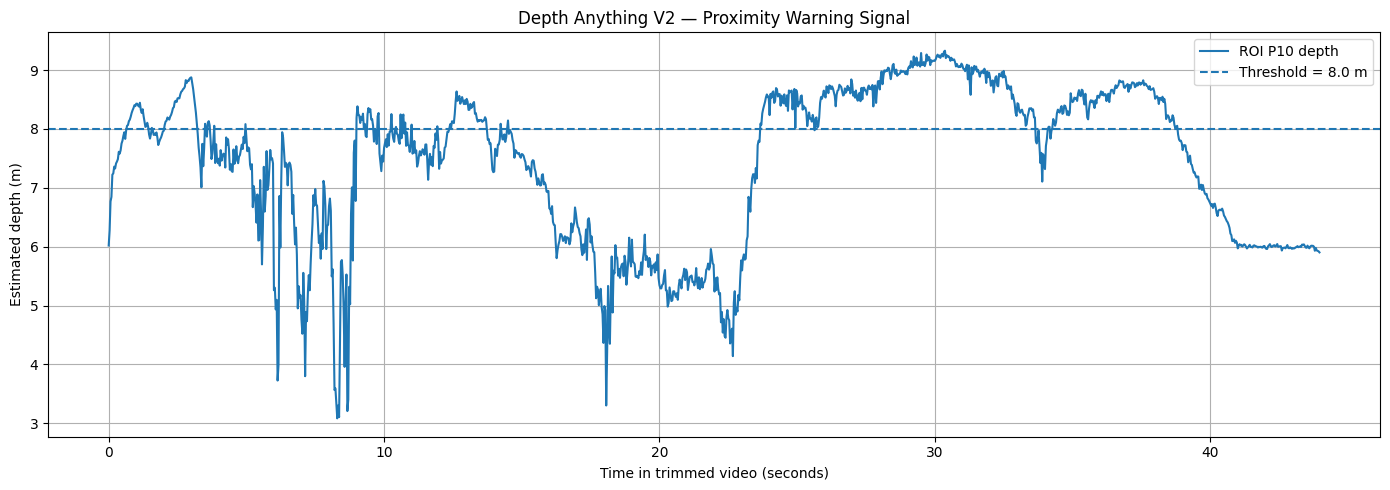

In [ ]:
# Plot P10 over time

plt.figure(figsize=(14, 5))

plt.plot(
    results_df["trimmed_time_s"],
    results_df["P10_m"],
    label="ROI P10 depth"
)

plt.axhline(
    WARNING_THRESHOLD_M,
    linestyle="--",
    label=f"Threshold = {WARNING_THRESHOLD_M:.1f} m"
)

plt.xlabel("Time in trimmed video (seconds)")
plt.ylabel("Estimated depth (m)")
plt.title("Depth Anything V2 — Proximity Warning Signal")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# Display the output video
display(Video(OUTPUT_VIDEO, embed=True, width=900))

In [ ]:
# Save Depth Anything metric-depth visualization as a video

cap = cv2.VideoCapture(INPUT_VIDEO)

if not cap.isOpened():
    raise RuntimeError(f"Could not open input video: {INPUT_VIDEO}")

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

os.makedirs(os.path.dirname(depth_output_path), exist_ok=True)

depth_writer = cv2.VideoWriter(
    depth_output_path,
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps,
    (width, height)
)

if not depth_writer.isOpened():
    cap.release()
    raise RuntimeError("Could not create the depth output video.")

# Use a fixed color scale across all frames for consistent visualization.
DEPTH_DISPLAY_MAX_M = 30.0

frame_count = 0
start_time = time.time()

while True:
    ret, frame = cap.read()

    if not ret:
        break

    # Predict metric depth in meters
    with torch.no_grad():
        depth_m = model.infer_image(frame)

    depth_m = np.asarray(depth_m, dtype=np.float32)

    # Resize depth map to original video resolution
    if depth_m.shape != (height, width):
        depth_m = cv2.resize(
            depth_m,
            (width, height),
            interpolation=cv2.INTER_LINEAR
        )

    # Convert metric depth to an 8-bit image for visualization.
    # Nearer regions appear toward the low end of the color scale.
    depth_clipped = np.clip(
        depth_m, 0, DEPTH_DISPLAY_MAX_M
    )

    depth_uint8 = (
        depth_clipped / DEPTH_DISPLAY_MAX_M * 255
    ).astype(np.uint8)

    # Apply a color map for visualization
    depth_color = cv2.applyColorMap(
        depth_uint8,
        cv2.COLORMAP_TURBO
    )

    depth_writer.write(depth_color)
    frame_count += 1

    if frame_count % 100 == 0:
        print(f"Processed {frame_count} frames")

cap.release()
depth_writer.release()

elapsed = time.time() - start_time

print("\nDepth video saved:")
print(depth_output_path)
print(f"Frames processed: {frame_count}")
print(f"Processing time: {elapsed:.1f} seconds")

# Display the generated depth video
display(Video(depth_output_path, embed=True, width=900))


Processed 100 frames
Processed 200 frames
Processed 300 frames
Processed 400 frames
Processed 500 frames
Processed 600 frames
Processed 700 frames
Processed 800 frames
Processed 900 frames
Processed 1000 frames
Processed 1100 frames
Processed 1200 frames


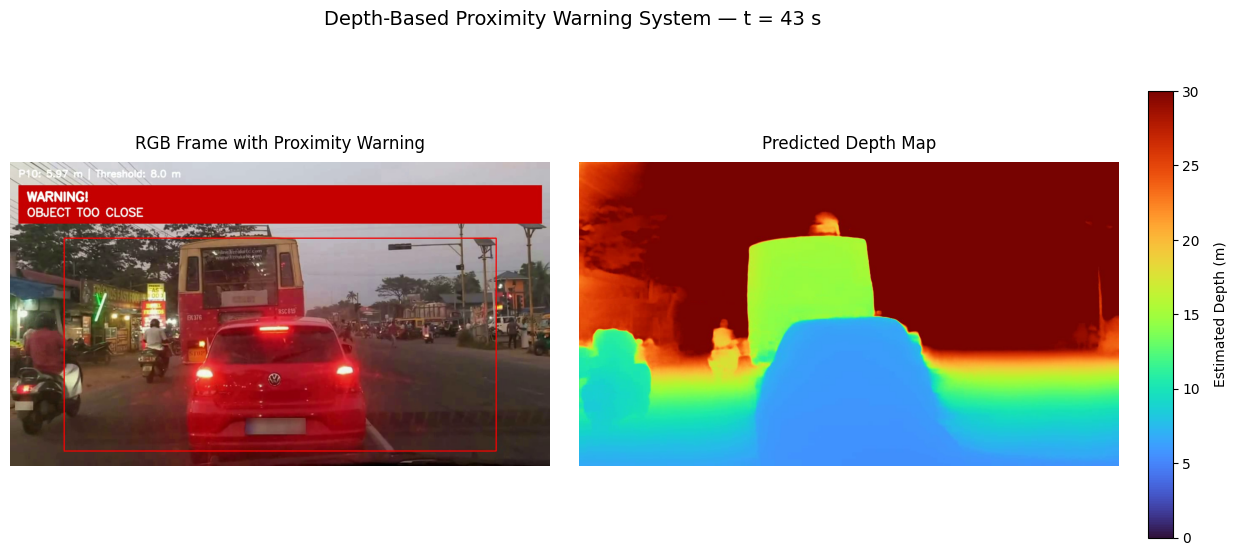

Saved image: /content/drive/MyDrive/Computer Vision/05/Roadscapes_Day_11/DepthAnything_Report_Frame_43s.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:


# --------------------------------------------------
# Paths
# --------------------------------------------------
base_dir = (
    "/content/drive/MyDrive/Computer Vision/05/"
    "Roadscapes_Day_11"
)

warning_video_path = str(
    Path(base_dir) / "Sequence_Day_11_metric_warning.mp4"
)

depth_video_path = str(
    Path(base_dir) / "Sequence_Day_11_metric_depth.mp4"
)

output_image_path = str(
    Path(base_dir) / "DepthAnything_Report_Frame_43s.png"
)

# --------------------------------------------------
# Extract the frame at 43 seconds
# --------------------------------------------------
TIME_S = 43

def read_frame_at_time(video_path, time_s):
    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        raise FileNotFoundError(
            f"Could not open video: {video_path}"
        )

    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    frame_index = round(time_s * fps)

    if frame_index >= total_frames:
        cap.release()
        raise ValueError(
            f"{time_s}s exceeds the video duration."
        )

    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_index)
    success, frame = cap.read()
    cap.release()

    if not success:
        raise RuntimeError(
            f"Could not read frame at {time_s}s."
        )

    # OpenCV uses BGR; Matplotlib expects RGB.
    return cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)


# Left: actual warning-video frame, including its overlay
rgb_frame = read_frame_at_time(
    warning_video_path, TIME_S
)

# Right: colorized depth frame, without warning text
depth_frame = read_frame_at_time(
    depth_video_path, TIME_S
)

# --------------------------------------------------
# Create the report figure
# --------------------------------------------------
fig = plt.figure(figsize=(15, 5.8))

gs = fig.add_gridspec(
    1, 3,
    width_ratios=[1, 1, 0.045],
    wspace=0.08
)

ax_rgb = fig.add_subplot(gs[0, 0])
ax_depth = fig.add_subplot(gs[0, 1])
cax = fig.add_subplot(gs[0, 2])

# Left panel: RGB frame with the warning overlay
ax_rgb.imshow(rgb_frame)
ax_rgb.set_title(
    "RGB Frame with Proximity Warning",
    fontsize=12,
    pad=10
)
ax_rgb.axis("off")

# Right panel: predicted depth visualization only
ax_depth.imshow(depth_frame)
ax_depth.set_title(
    "Predicted Depth Map",
    fontsize=12,
    pad=10
)
ax_depth.axis("off")

# Color scale: matches the fixed 0–30 m TURBO visualization
norm = mpl.colors.Normalize(vmin=0, vmax=30)

scalar_map = mpl.cm.ScalarMappable(
    norm=norm,
    cmap="turbo"
)
scalar_map.set_array([])

colorbar = fig.colorbar(
    scalar_map,
    cax=cax,
    ticks=[0, 5, 10, 15, 20, 25, 30]
)
colorbar.set_label(
    "Estimated Depth (m)",
    fontsize=10,
    labelpad=10
)

fig.suptitle(
    f"Depth-Based Proximity Warning System — t = {TIME_S} s",
    fontsize=14,
    y=1.02
)

plt.savefig(
    output_image_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

# Display the figure in the notebook
plt.show()

print(f"Saved image: {output_image_path}")

# Download the PNG to your computer
files.download(output_image_path)


# Future Work

Some improvements can be considered for future development:

* **Object Detection and Tracking:** Integrate an object detection model to identify and track nearby vehicles, pedestrians, and other road users.
* **Adaptive Warning Thresholds:** Investigate adaptive distance thresholds to generate warnings based on object proximity and driving conditions.
